# Week 6 Assignment
## Clustering & PCA on Real Credit Card Data
### Name: Yasaa Usman Ahmad Khan

**Submit as:** this notebook only -- no separate report this week

## Note

This week's lab used a synthetic loan dataset built specifically to show raw features getting dominated by a wealth axis. This assignment uses **real data**.


## The Dataset

**Default of Credit Card Clients** — 30,000 real credit card customers in Taiwan, 2005. UCI Machine Learning Repository, donated by I-Cheng Yeh. CC BY 4.0 licensed.

Source: https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients

**Citation (include this in your report):** Yeh, I. (2009). *Default of Credit Card Clients* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H

| Column(s) | Meaning |
|---|---|
| `LIMIT_BAL` | Credit limit (NT dollars) |
| `SEX`, `EDUCATION`, `MARRIAGE`, `AGE` | Demographics |
| `PAY_0` ... `PAY_6` | Monthly repayment status, Apr-Sep 2005 (-1=paid on time, 1+=months late) |
| `BILL_AMT1` ... `BILL_AMT6` | Monthly bill statement amount, Apr-Sep 2005 |
| `PAY_AMT1` ... `PAY_AMT6` | Monthly amount actually paid, Apr-Sep 2005 |
| `default.payment.next.month` | Target: did they default the following month? (1/0) |

## Setup — Load the Data
Run this cell to fetch the dataset.

In [1]:
# pip install ucimlrepo   (uncomment if not already installed)
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

dataset = fetch_ucirepo(id=350)
X_raw = dataset.data.features
y = dataset.data.targets
df = pd.concat([X_raw, y], axis=1)

print('Shape:', df.shape)
df.head(3)

Shape: (30000, 24)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


---
## Part 1 — Explore and Decide

Before clustering anything, investigate the data yourself.

- Check summary statistics for every numeric column (`.describe()`). Which columns look right-skewed? Which look roughly symmetric or already bounded?
- Check for missing values and any values that look like data errors, not real measurements (the UCI documentation itself doesn't flag any — confirm that for yourself rather than assuming).
- Decide which columns you'll treat as **raw/size-scaled** (candidates for wealth dominance, the way `total_assets` etc. were in the lab) and which you'll treat as **already bounded/ratio-like** (comparable to `credit_score` in the lab). Write down your reasoning, not just your final list.

In [2]:
import numpy as np
from scipy.stats import skew

# The repository hands back generic names (X1..X23, Y). UCI's own variable table says what each one is,
# so I rename from that table instead of typing a mapping by hand. I call the target `default`
# (the same name next week's notebook uses) so this code carries forward unchanged.
names = dataset.variables.set_index("name")["description"].to_dict()
df = df.rename(columns={c: names[c] for c in df.columns if c.startswith("X")})
df = df.rename(columns={"Y": "default"})

print("Columns:", df.columns.tolist())
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
print("Default rate:", round(df["default"].mean(), 4))

Columns: ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default']
Shape: (30000, 24)
Missing values: 0 | duplicate rows: 35
Default rate: 0.2212


In [3]:
MONEY = ["LIMIT_BAL"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]
STATUS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
CODES = ["SEX", "EDUCATION", "MARRIAGE"]
num_cols = MONEY + ["AGE"] + STATUS

summary = df[num_cols].describe().T[["min", "25%", "50%", "75%", "max"]]
summary["skew"] = [skew(df[c]) for c in num_cols]
summary["right-skewed (skew > 1)?"] = summary["skew"] > 1
summary.round(2)

,min,25%,50%,75%,max,skew,right-skewed (skew > 1)?
LIMIT_BAL,10000.0,50000.00,140000.0,240000.00,1000000.0,0.99,False
BILL_AMT1,-165580.0,3558.75,22381.5,67091.00,964511.0,2.66,True
BILL_AMT2,-69777.0,2984.75,21200.0,64006.25,983931.0,2.71,True
BILL_AMT3,-157264.0,2666.25,20088.5,60164.75,1664089.0,3.09,True
BILL_AMT4,-170000.0,2326.75,19052.0,54506.00,891586.0,2.82,True
BILL_AMT5,-81334.0,1763.00,18104.5,50190.50,927171.0,2.88,True
BILL_AMT6,-339603.0,1256.00,17071.0,49198.25,961664.0,2.85,True
PAY_AMT1,0.0,1000.00,2100.0,5006.00,873552.0,14.67,True
PAY_AMT2,0.0,833.00,2009.0,5000.00,1684259.0,30.45,True
PAY_AMT3,0.0,390.00,1800.0,4505.00,896040.0,17.22,True


In [4]:
# Values that look like data errors, not real measurements
neg_zero = pd.DataFrame({"negative": (df[MONEY] < 0).sum(), "zero": (df[MONEY] == 0).sum()})
print("Money columns with negative or zero values:")
print(neg_zero[(neg_zero.negative > 0) | (neg_zero.zero > 0)].T.to_string())

print("\nBills above the credit limit (BILL_AMT1 > LIMIT_BAL):", int((df["BILL_AMT1"] > df["LIMIT_BAL"]).sum()))

print("\nCategory codes vs the documentation (EDUCATION 1-4, MARRIAGE 1-3, SEX 1-2):")
for c in CODES:
    print(f"  {c}:", df[c].value_counts().sort_index().to_dict())
print("  EDUCATION rows with an undocumented code:", int((~df["EDUCATION"].isin([1, 2, 3, 4])).sum()))
print("  MARRIAGE rows with an undocumented code:", int((~df["MARRIAGE"].isin([1, 2, 3])).sum()))

print("\nRepayment status codes (documentation mentions -1 and 1 or more only):")
print(pd.concat({c: df[c].value_counts().sort_index() for c in STATUS}, axis=1).fillna(0).astype(int).to_string())

Money columns with negative or zero values:
          BILL_AMT1  BILL_AMT2  BILL_AMT3  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  PAY_AMT4  PAY_AMT5  PAY_AMT6
negative        590        669        655        675        655        688         0         0         0         0         0         0
zero           2008       2506       2870       3195       3506       4020      5249      5396      5968      6408      6703      7173

Bills above the credit limit (BILL_AMT1 > LIMIT_BAL): 2115

Category codes vs the documentation (EDUCATION 1-4, MARRIAGE 1-3, SEX 1-2):
  SEX: {1: 11888, 2: 18112}
  EDUCATION: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
  MARRIAGE: {0: 54, 1: 13659, 2: 15964, 3: 323}
  EDUCATION rows with an undocumented code: 345
  MARRIAGE rows with an undocumented code: 54

Repayment status codes (documentation mentions -1 and 1 or more only):
    PAY_0  PAY_2  PAY_3  PAY_4  PAY_5  PAY_6
-2   2759   3782   4085   4348   4546   4895
-1   5686

In [5]:
# My classification, decided from the evidence above (data type and range), not from the default column
RAW_SIZE = MONEY            # 13 money amounts: they grow with how big the account is
BOUNDED = ["AGE"] + STATUS  # small fixed ranges that do not grow with account size
# SEX, EDUCATION, MARRIAGE are category codes (1, 2, 3 are labels, not amounts), so I leave them out of distance-based methods.

print("Raw / size-scaled (", len(RAW_SIZE), "):", RAW_SIZE)
print("Bounded            (", len(BOUNDED), "):", BOUNDED)
print("Left out (category codes):", CODES)

Raw / size-scaled ( 13 ): ['LIMIT_BAL', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
Bounded            ( 7 ): ['AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
Left out (category codes): ['SEX', 'EDUCATION', 'MARRIAGE']


**Write-up:** Which columns did you classify as raw/size-scaled, and why? Which as already-bounded?

**Raw / size-scaled (13 columns):** `LIMIT_BAL`, `BILL_AMT1` to `BILL_AMT6`, `PAY_AMT1` to `PAY_AMT6`. These are amounts in NT dollars, so they grow with how big a customer's account is. They are also heavily right-skewed (the six bills have skew 2.66 to 3.09, the six payments 10.64 to 30.45, `LIMIT_BAL` 0.99), and the six bill columns are close to copies of each other, which is exactly the setup where one "size" direction can dominate.

**Already bounded (7 columns):** `AGE` (21 to 79, skew 0.73) and the six repayment statuses `PAY_0`, `PAY_2` to `PAY_6` (small fixed codes from -2 to 8). None of them grow with account size.

**Left out of clustering:** `SEX`, `EDUCATION`, `MARRIAGE`. They are category codes (1, 2, 3 are labels, not amounts), so distances between them mean nothing.

I decided this from data type and range, not by looking at which columns predict `default`.

**What the checks found.** There are no missing values and 35 duplicate rows (I kept them; the ID column is not in the features, so identical rows may be different customers). The data does not match the documentation in several places: `EDUCATION` has codes 0, 5 and 6 (345 rows) although only 1 to 4 are documented, `MARRIAGE` has code 0 (54 rows) although only 1 to 3 are documented, and the `PAY_*` columns use -2 and 0, which the documentation never mentions (0 is the most common value in every `PAY_*` column). Status 1 also appears 3,688 times in `PAY_0` but only 28, 4, 2, 0 and 0 times in `PAY_2` to `PAY_6`, which suggests `PAY_0` is coded differently from the others. The bills include 590 to 688 negative values per month (most likely overpayments), and 2,115 customers have a latest bill above their credit limit. I did not drop or change any rows, because I cannot tell which of these are errors and which are real, but I will keep them in mind.

---
## Part 2 — Raw-Feature Clustering and PCA

Using the raw, size-scaled columns you identified in Part 1 (plus any bounded columns you think belong):

- Scale the data appropriately.
- Use the elbow method to choose K. Justify your choice — is the elbow sharp or soft? Is it different from what you saw in the lab?
- Fit K-Means with your chosen K. Profile each cluster: what's the mean credit limit, mean age, and most importantly, the **default rate** in each cluster?
- Run PCA. How many components would you keep, and by what criterion (80% variance? keeping the dominant axis intact? something else)? Justify your choice — don't just default to a number because the lab used it.
- Build a loadings table for PC1. What dominates it? Is it the same *kind* of pattern as the lab's wealth axis, or something different?

**Keep this code.** You'll reuse it directly as the starting point for next week's extension.

,inertia,drop,drop as % of K=1 inertia
K,,,
1,600000.0,NaN,NaN
2,478544.3,121455.7,20.2
3,399460.7,79083.6,13.2
4,369337.5,30123.2,5.0
5,345551.3,23786.2,4.0
6,325087.0,20464.3,3.4
7,311365.5,13721.6,2.3
8,299831.4,11534.1,1.9
9,287662.7,12168.8,2.0


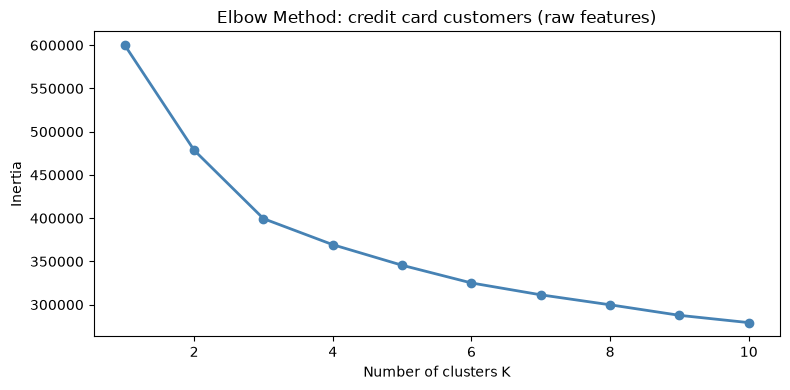

In [6]:
RAW_FEATURES = RAW_SIZE + BOUNDED
X_s = StandardScaler().fit_transform(df[RAW_FEATURES])

K_range = range(1, 11)
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_s).inertia_ for k in K_range]

elbow = pd.DataFrame({"K": list(K_range), "inertia": inertias})
elbow["drop"] = -elbow["inertia"].diff()
elbow["drop as % of K=1 inertia"] = 100 * elbow["drop"] / inertias[0]
display(elbow.round(1).set_index("K"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(K_range), inertias, "o-", color="steelblue", linewidth=2)
ax.set_xlabel("Number of clusters K"); ax.set_ylabel("Inertia")
ax.set_title("Elbow Method: credit card customers (raw features)")
plt.tight_layout(); plt.show()

**Choosing K.** As a share of the K=1 inertia, the drops are 20.2% (K=2), 13.2% (K=3), then 5.0% (K=4), 4.0%, 3.4%, 2.3%, 1.9%, 2.0% and 1.4%. There are two big steps and then a clear flattening between K=3 and K=4, so I chose **K = 3**. The elbow is moderately sharp, not razor sharp: K=4 still gains 5.0% and nothing is crisp after that.

It is different from the lab. In the lab, one split did almost all the work (K=2 dropped 1061 of 4800, which is 22.1%, then K=3 only 5.6%) and the later drops bounced around (K=6 dropped 247, more than K=5's 157). Here the curve falls smoothly with two real steps.

One caution about the choice: I also fit K=4 as a check (printed above). At K=4 a cluster of 2,914 customers (9.7% of everyone) appears with a default rate of 62.8% and a mean `PAY_0` of 1.64. At K=3 that group is hidden inside cluster 0. So the elbow K is not necessarily the most useful K for finding risk. I stayed with K=3 because it is the elbow and it keeps next week's comparison fair.

In [7]:
K = 3
km = KMeans(n_clusters=K, random_state=42, n_init=10).fit(X_s)
raw_labels = km.labels_

def profile(labels):
    return (df.assign(cluster=labels).groupby("cluster")
              .agg(size=("default", "size"), mean_credit_limit=("LIMIT_BAL", "mean"), mean_age=("AGE", "mean"),
                   default_rate=("default", "mean"), mean_PAY_0=("PAY_0", "mean"), mean_BILL_AMT1=("BILL_AMT1", "mean"))
              .round(3))

print(f"K = {K} cluster profile (overall default rate {df['default'].mean():.3f}):")
display(profile(raw_labels))

# A check on the choice: what does one more cluster do?
km4 = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_s)
print("For comparison, K = 4:")
display(profile(km4.labels_))

K = 3 cluster profile (overall default rate 0.221):


,size,mean_credit_limit,mean_age,default_rate,mean_PAY_0,mean_BILL_AMT1
cluster,,,,,,
0,15924,107360.085,34.521,0.266,0.418,45037.564
1,10519,219121.590,36.434,0.165,-0.766,10058.698
2,3557,283943.683,37.000,0.189,0.251,200650.636


For comparison, K = 4:


,size,mean_credit_limit,mean_age,default_rate,mean_PAY_0,mean_BILL_AMT1
cluster,,,,,,
0,2914,77028.140,34.946,0.628,1.640,38763.263
1,9561,223741.240,36.690,0.163,-0.809,8931.520
2,3358,288275.068,37.060,0.182,0.213,204832.196
3,14167,119492.624,34.411,0.186,0.123,45918.191


,explained variance,cumulative,eigenvalue
PC1,0.327,0.327,6.539
PC2,0.203,0.530,4.062
PC3,0.075,0.605,1.509
PC4,0.050,0.656,1.003
PC5,0.046,0.702,0.923
PC6,0.044,0.746,0.888
PC7,0.044,0.790,0.874
PC8,0.039,0.829,0.784
PC9,0.037,0.866,0.733
PC10,0.035,0.901,0.700


Components with eigenvalue > 1 (Kaiser rule): 4
Components needed for 80% of the variance:     8


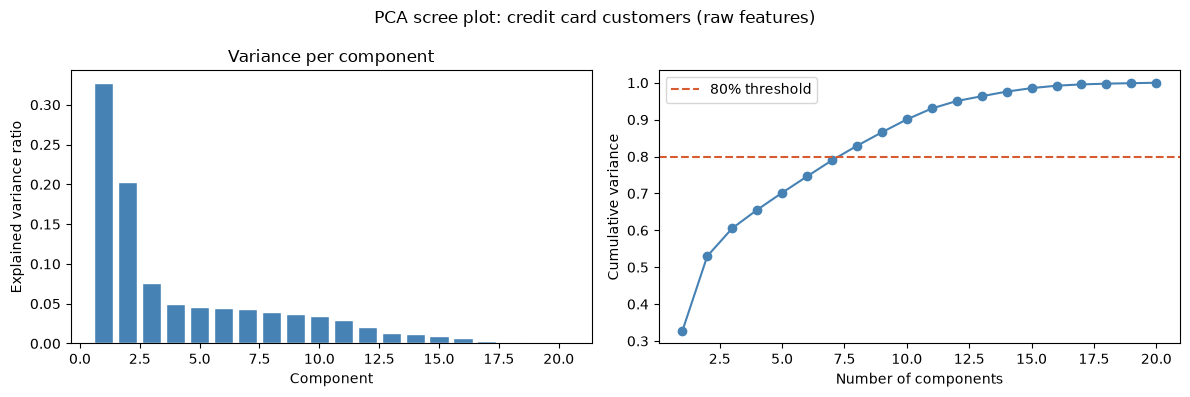

In [8]:
pca_full = PCA().fit(X_s)
evr = pca_full.explained_variance_ratio_
eigenvalues = pca_full.explained_variance_

pc_table = pd.DataFrame({"explained variance": evr, "cumulative": evr.cumsum(), "eigenvalue": eigenvalues},
                        index=[f"PC{i}" for i in range(1, len(evr) + 1)])
display(pc_table.round(3))

n_kaiser = int((eigenvalues > 1).sum())          # Kaiser rule: keep components worth more than one original feature
n_80 = int(np.argmax(evr.cumsum() >= 0.80)) + 1  # smallest count reaching 80% of the variance
print(f"Components with eigenvalue > 1 (Kaiser rule): {n_kaiser}")
print(f"Components needed for 80% of the variance:     {n_80}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, len(evr) + 1), evr, color="steelblue", edgecolor="white")
axes[0].set_xlabel("Component"); axes[0].set_ylabel("Explained variance ratio"); axes[0].set_title("Variance per component")
axes[1].plot(range(1, len(evr) + 1), evr.cumsum(), "o-", color="steelblue")
axes[1].axhline(0.80, color="#D85A30", linestyle="--", label="80% threshold")
axes[1].set_xlabel("Number of components"); axes[1].set_ylabel("Cumulative variance"); axes[1].legend()
plt.suptitle("PCA scree plot: credit card customers (raw features)")
plt.tight_layout(); plt.show()

raw_pca_pc1_variance = evr[0]

In [9]:
print("PC4 eigenvalue:", round(float(eigenvalues[3]), 3), "(Kaiser cutoff is 1.0). Its three largest loadings:",
      pd.Series(pca_full.components_[3], index=RAW_FEATURES).sort_values(key=abs, ascending=False).head(3).round(3).to_dict())

N_COMPONENTS = 3
print("\nComponents kept:", N_COMPONENTS, f"-> {evr[:N_COMPONENTS].sum():.1%} of the variance")

loadings = pd.DataFrame(pca_full.components_[:N_COMPONENTS].T, index=RAW_FEATURES,
                        columns=[f"PC{i}" for i in range(1, N_COMPONENTS + 1)])
print("\nPC1 loadings, largest magnitude first:")
display(loadings["PC1"].sort_values(key=abs, ascending=False).round(3).to_frame())

print("PC2 and PC3: the three largest loadings each")
for pc in loadings.columns[1:]:
    top = loadings[pc].sort_values(key=abs, ascending=False).head(3).round(3)
    print(f"  {pc}:", top.to_dict())

Z = pca_full.transform(X_s)
print("\nCorrelation of each kept component's score with default:")
print({f"PC{i+1}": round(float(np.corrcoef(Z[:, i], df['default'])[0, 1]), 3) for i in range(N_COMPONENTS)})

PC4 eigenvalue: 1.003 (Kaiser cutoff is 1.0). Its three largest loadings: {'AGE': 0.965, 'LIMIT_BAL': 0.195, 'PAY_AMT2': -0.054}

Components kept: 3 -> 60.5% of the variance

PC1 loadings, largest magnitude first:


,PC1
BILL_AMT4,0.354
BILL_AMT5,0.352
BILL_AMT3,0.350
BILL_AMT2,0.346
BILL_AMT6,0.345
BILL_AMT1,0.335
PAY_5,0.210
PAY_4,0.206
PAY_6,0.206
PAY_3,0.199


PC2 and PC3: the three largest loadings each
  PC2: {'PAY_4': 0.348, 'PAY_3': 0.347, 'PAY_2': 0.338}
  PC3: {'PAY_AMT2': 0.437, 'PAY_AMT1': 0.401, 'PAY_AMT3': 0.397}

Correlation of each kept component's score with default:
{'PC1': 0.083, 'PC2': 0.286, 'PC3': 0.0}


**How many components.** The eigenvalues are 6.54, 4.06, 1.51, 1.003 and 0.92 for PC1 to PC5. Two common rules disagree. The 80% rule needs 8 components (82.9%), but after PC3 the variance is spread thinly (PC4 to PC10 are only 3.5% to 5.0% each). The Kaiser rule (keep eigenvalues above 1) technically says 4, but PC4's eigenvalue is 1.003, right on the cutoff, and its largest loading is `AGE` at 0.965. That makes PC4 basically `AGE` on its own, a feature that does not move with anything else, not a pattern across features. So I keep **3 components (60.5% of the variance)**: PC1, PC2 and PC3 are clearly above 1 and each is a real group of columns. I did not copy the lab's choice of 4.

**PC1 (32.7% of the variance).** The six `BILL_AMT` columns carry almost all of it (loadings 0.335 to 0.354 each), followed by the `PAY_*` statuses (0.160 to 0.210). `LIMIT_BAL` loads only 0.070 and `AGE` 0.013. So PC1 is a "size of what you owe" axis: the six bills are near copies of each other, so one direction soaks up their shared variance.

It is the same kind of pattern as the lab's wealth axis (a big first component built from a group of columns that all scale with account size: 33.3% in the lab, 32.7% here), but the content is different. The lab's axis was what applicants own (income, assets, collateral); this one is what customers owe, and the credit limit barely loads on it. It also tracks default only weakly: the correlation of PC1 scores with default is 0.083, compared with 0.286 for PC2, the repayment-delay axis (`PAY_2` to `PAY_4`, loadings 0.338 to 0.348). PC3 (7.5%) is a payments-made axis (`PAY_AMT1` to `PAY_AMT3`, loadings about 0.40 to 0.44) and has a correlation of 0.0 with default.

**Write-up:** Do your raw-feature clusters separate applicants by actual default risk, or by something else? Support your answer with actual numbers from your cluster profile table.

**Mostly by something else: account size and spending, with only a blurry risk signal.** At K=3 the clusters look like this:

| Cluster | Customers | Mean credit limit | Mean latest bill | Default rate |
|---|---|---|---|---|
| 0 | 15,924 | 107,360 | 45,038 | 0.266 |
| 1 | 10,519 | 219,122 | 10,059 | 0.165 |
| 2 | 3,557 | 283,944 | 200,651 | 0.189 |

Clusters 1 and 2 differ about 20 times in latest bill (10,059 vs 200,651) and by about 65,000 in credit limit, yet their default rates differ by only 2.4 points (0.165 vs 0.189). That is size separating them, not risk. All three rates sit within 10.1 points of each other (0.165 to 0.266, overall 0.221).

Some risk does leak in: cluster 0 has the lowest limits, the highest default rate, and a mean `PAY_0` of 0.42 against -0.77 in cluster 1. But the group that really stands out (2,914 customers defaulting 62.8% of the time at K=4) is not separated at K=3. So the raw features contain the risk signal, but the K=3 clustering mainly sorts customers by how big their accounts are.

---
## Part 3 — Reflection

A few quick questions — a sentence or two each is enough. This is not a formal report; that comes with next week's extension, once you have both the raw and engineered results to compare.

1. What was the single most surprising thing you found in Part 1 or Part 2?

That the elbow's K hides the riskiest group. At K=3 the clusters look like a size ranking (default 16.5%, 18.9%, 26.6%), but one more cluster at K=4 pulls out 2,914 customers who default 62.8% of the time and are on average 1.64 months late on the latest payment status. The signal was in the raw features all along (the `PAY_*` columns were in my feature list); K=3 just did not split it off.

2. Based on what you saw in the loadings table, which raw features do you expect will matter most once you engineer ratio features next week — and why?

The six `BILL_AMT` columns dominate PC1 (0.335 to 0.354) but are near copies of each other, so expressing a bill as a share of `LIMIT_BAL` (utilization) should strip out the size and keep the useful part. The `PAY_*` status columns drive PC2, which correlates with default at 0.286, so summarizing them (how many months late, which way the trend goes) should matter most, and the `PAY_AMT` columns, which drive PC3, should matter once they are compared with the bill they pay off. `LIMIT_BAL` will matter mostly as the denominator.

3. Is there anything about this real dataset that surprised you compared to the Week 6 lab's synthetic data (e.g. the shape of the elbow, how dominant PC1 was, anything else)?

Three things. (1) The elbow had two real steps (20.2% and 13.2%) and then a smooth decline, where the lab's had one big step and bounced around later. (2) PC1 explained almost the same share (32.7% vs 33.3% in the lab), but it was made of bills rather than wealth, and the credit limit barely loaded on it (0.070). (3) The raw clusters tracked default less than the lab's did: rates spread 10.1 points (0.165 to 0.266) here versus 21.6 points (0.271 to 0.487) in the lab. The real data was also messier: undocumented codes, negative bills, and a `PAY_0` column that seems coded differently, none of which the synthetic data had.